## 检查标签文件数量以及大小为 0 的标签文件数量

In [1]:
import os
def count_files_and_zero_size(directory):
    """
    计算给定目录下 .txt 文件的总数和大小为 0 的 .txt 文件数

    参数：
    directory (str): 需要检查的目录路径

    返回：
    tuple: 包含两个整数的元组，第一个是 .txt 文件总数，第二个是大小为 0 的 .txt 文件数
    """
    total_files = 0
    zero_size_files = 0

    # 遍历目录中的每个文件
    for filename in os.listdir(directory):
        # 检查文件是否以 .txt 结尾
        if filename.endswith('.txt'):
            file_path = os.path.join(directory, filename)
            total_files += 1
            # 检查文件大小是否为 0
            if os.path.getsize(file_path) == 0:
                zero_size_files += 1
    
    return total_files, zero_size_files

In [2]:
# 指定要检查的目录路径
directory_path = 'AccidentsDetectionYOLOv8/train/labels'
# 调用函数计算 .txt 文件总数和大小为 0 的文件数
total_files, zero_size_files = count_files_and_zero_size(directory_path)

# 打印结果
print(f" 文件总数量：{total_files}")
print(f" 大小为 0 的文件数量：{zero_size_files}")

 文件总数量：10469
 大小为 0 的文件数量：259


## 复制数据集到目标目录并删除大小为 0 的 .txt 文件

In [3]:
# 完整复制目录下的所有内容
import shutil

# 定义源目录和目标目录
source_directory = 'AccidentsDetectionYOLOv8'
destination_directory = 'datasets'

# 确保目标目录存在
if not os.path.exists(destination_directory):
    os.makedirs(destination_directory)

# 复制整个目录及其内容
shutil.copytree(source_directory, destination_directory, dirs_exist_ok = True)

# 打印复制完成的消息
print(f" 所有文件和目录均已从 {source_directory} 到 {destination_directory}")

 所有文件和目录均已从 AccidentsDetectionYOLOv8 到 datasets


#### 删除无事故的图片和标签文件

In [4]:
import os

def delete_zero_size_files(base_directory):
    """
    删除给定目录下大小为零的标签文件及其对应的图片文件

    参数：
    base_directory (str): 数据集的基目录路径
    
    此函数遍历训练(train)、验证(valid)和测试(test)数据集的标签文件
    检查其大小，如果文件大小为零，则删除该标签文件及其对应的图片文件
    """
    # 遍历数据集类型：训练、验证、测试
    for dataset_type in ["train", "valid", "test"]:
        # 构建标签和图片目录路径
        labels_dir = os.path.join(base_directory, dataset_type, 'labels')
        images_dir = os.path.join(base_directory, dataset_type, 'images')

        # 检查必要的目录是否存在
        if not os.path.exists(labels_dir) or not os.path.exists(images_dir):
            print(f"所需的目录之一不存在于 {dataset_type}:")
            print(f"标签目录：{labels_dir}")
            print(f"图片目录：{images_dir}")
            continue

        # 遍历标签目录下的所有文件
        for filename in os.listdir(labels_dir):
            if filename.endswith('.txt'):
                file_path = os.path.join(labels_dir, filename)
                # 检查文件大小，如果为零则进行删除操作
                if os.path.getsize(file_path) == 0:
                    # 假设图片格式为 .jpg
                    image_filename = filename.replace('.txt', '.jpg')
                    image_file_path = os.path.join(images_dir, image_filename)

                    # 删除标签文件
                    try:
                        os.remove(file_path)
                        print(f"已删除的标签文件：{file_path}")
                    except Exception as e:
                        print(f"删除标签文件时出错 {file_path}: {e}")

                    # 删除对应的图片文件
                    try:
                        if os.path.exists(image_file_path):
                            os.remove(image_file_path)
                            print(f"已删除的图片文件：{image_file_path}")
                        else:
                            print(f"图片文件未找到：{image_file_path}")
                    except Exception as e:
                        print(f"删除图片文件时出错 {image_file_path}: {e}")

In [5]:
# 指定数据集的基目录
base_directory = 'datasets'
# 调用函数清理数据集中的零大小文件
delete_zero_size_files(base_directory)

已删除的标签文件：datasets/train/labels/maxresdefault_jpg.rf.287cc7b414dfe7d7644220b82052a228.txt
已删除的图片文件：datasets/train/images/maxresdefault_jpg.rf.287cc7b414dfe7d7644220b82052a228.jpg
已删除的标签文件：datasets/train/labels/non-accident-74-_jpg.rf.d63ef1be5eb0b3f2970d7d6867324afa.txt
已删除的图片文件：datasets/train/images/non-accident-74-_jpg.rf.d63ef1be5eb0b3f2970d7d6867324afa.jpg
已删除的标签文件：datasets/train/labels/non-accident-56-_jpg.rf.6733b93c6eba50f314f8fa36a7862f65.txt
已删除的图片文件：datasets/train/images/non-accident-56-_jpg.rf.6733b93c6eba50f314f8fa36a7862f65.jpg
已删除的标签文件：datasets/train/labels/non-accident-23-_jpg.rf.b921e873594f1a98565352800d740b99.txt
已删除的图片文件：datasets/train/images/non-accident-23-_jpg.rf.b921e873594f1a98565352800d740b99.jpg
已删除的标签文件：datasets/train/labels/non-accident-58-_jpg.rf.014da4bc0f22fd08f640de0d0fed04db.txt
已删除的图片文件：datasets/train/images/non-accident-58-_jpg.rf.014da4bc0f22fd08f640de0d0fed04db.jpg
已删除的标签文件：datasets/train/labels/non-accident-58-_jpg.rf.dc4ef58a3b4444e72a11fa902b0a506

In [7]:
directory_path = 'datasets/train/labels'
total_files, zero_size_files = count_files_and_zero_size(directory_path)
# 打印结果
print(f"文件总数量：{total_files}")
print(f"大小为 0 的文件数量：{zero_size_files}")

文件总数量：10210
大小为 0 的文件数量：0


## 数据集探索

In [8]:
# 随机展示任意指定数量的事故图片，并标注事故车辆
import os
import random
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def load_image_and_labels(image_path, label_path):
    """加载图片和对应的标签文件"""
    image = Image.open(image_path)
    with open(label_path, 'r') as f:
        labels = f.readlines()
    return image, labels

def draw_bounding_boxes(image, labels, width, height):
    """在图片上绘制边界框"""
    draw = ImageDraw.Draw(image)
    for label in labels:
        class_id, x_center, y_center, bbox_width, bbox_height = map(float, label.split())

        # 将 YOLO 格式转换为像素坐标
        x_min = (x_center - bbox_width / 2) * width
        y_min = (y_center - bbox_height / 2) * height
        x_max = (x_center + bbox_width / 2) * width
        y_max = (y_center + bbox_height / 2) * height

        # 绘制边界框
        draw.rectangle([x_min, y_min, x_max, y_max], outline = 'red', width = 3)

def display_images_with_bboxes(base_directory, num_images = 4):
    """随机显示指定数量的图片及其边界框"""
    images_dir = os.path.join(base_directory, 'images')
    labels_dir = os.path.join(base_directory, 'labels')

    # 获取所有图片文件名
    image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg')]
    selected_images = random.sample(image_files, num_images)

    fig, axes = plt.subplots(1, num_images, figsize = (15, 5))

    for i, img_file in enumerate(selected_images):
        img_path = os.path.join(images_dir, img_file)
        label_file = img_file.replace('.jpg', '.txt')
        label_path = os.path.join(labels_dir, label_file)

        if not os.path.exists(label_path):
            print(f"未找到标签文件对应于 {img_path}")
            continue

        image, labels = load_image_and_labels(img_path, label_path)
        draw_bounding_boxes(image, labels, image.width, image.height)

        # 显示图片
        ax = axes[i] if num_images > 1 else axes
        ax.imshow(image)
        ax.axis('off')    

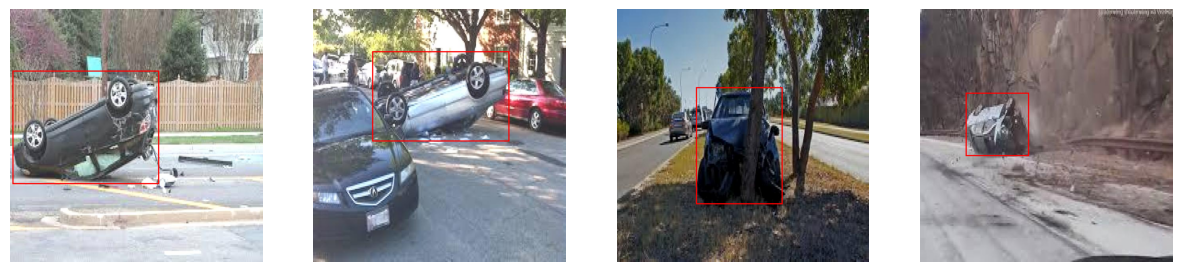

In [9]:
base_directory = 'datasets/train'
display_images_with_bboxes(base_directory)

## 修改 data.yaml 文件内容

In [1]:
# 安装 pyyaml 库（如果尚未安装）
!pip install pyyaml

In [3]:
# 导入必要的库
import yaml

# 定义 YAML 文件路径
yaml_file_path = 'datasets/data.yaml'

# 读取 YAML 文件内容
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)

# 打印原始内容（可选）
print(" 原始内容： ")
data

 原始内容： 


{'train': '/kaggle/input/accidents-detection-dataset/AccidentsDetectionYOLOv8/train/images',
 'val': '/kaggle/input/accidents-detection-dataset/AccidentsDetectionYOLOv8/valid/images',
 'test': '/kaggle/input/accidents-detection-dataset/AccidentsDetectionYOLOv8/test/images',
 'nc': 2,
 'names': ['moderate', 'severe']}

In [4]:
# 修改内容
data['train'] = '../train/images'
data['val'] = '../valid/images'
data['test'] = '../test/images'

# 打印修改后的内容
print("\n 修改后的内容：")
data


 修改后的内容：


{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 2,
 'names': ['moderate', 'severe']}

In [5]:
# 保存修改后的内容回 YAML 文件
with open(yaml_file_path, 'w') as file:
    yaml.safe_dump(data, file)

# 确认保存成功
with open(yaml_file_path, 'r') as file:
    saved_data = yaml.safe_load(file)
print("\n确认保存的内容：")
saved_data


确认保存的内容：


{'names': ['moderate', 'severe'],
 'nc': 2,
 'test': '../test/images',
 'train': '../train/images',
 'val': '../valid/images'}